# 99. 종합 판정: 가설 15개 최종표 + 통계로 갈지, 딥러닝까지 갈지

**먼저 H01~H15 노트북을 모두 실행**해야 합니다. 각 노트북이 results/ 폴더에 판정을 저장하고, 이 노트북이 그것을 모읍니다.

1. 가설 15개 최종표 (p-값, 효과 크기, 판정)
2. 정상성 요약 (H05)
3. 딥러닝 비교 실험: 1D-CNN vs LDA·RF (순서 블록, McNemar)
4. 판단 기준과 결론

In [1]:
from common import *
cyc = load_cycles()
print(cyc.shape)

(2205, 75)


## 1. 가설 15개 최종표

In [2]:
files = sorted(RESULTS.glob("H*.json"))
tbl = pd.DataFrame([dict(가설=f.stem, **json.loads(f.read_text(encoding="utf-8"))) for f in files])
cols = ["가설", "title", "test", "stat", "p", "effect", "verdict"] + [c for c in ["note"] if c in tbl.columns]
pd.set_option("display.max_colwidth", 80)
display(tbl[cols].rename(columns={"title": "내용", "test": "검정", "stat": "통계량", "p": "p (Holm)", "effect": "효과 크기", "verdict": "판정", "note": "비고"}))
full = tbl.verdict.str.contains("기각|비정상") & ~tbl.verdict.str.contains("외|쌍|일부|작음")
part = tbl.verdict.str.contains("외|쌍|일부"); tiny = tbl.verdict.str.contains("작음")
print(f"가설 {len(tbl)}개: 대립가설 지지 {full.sum()}개 / 일부 그룹·쌍만 지지 {part.sum()}개 ({', '.join(tbl.가설[part])}) / "
      f"유의하지만 효과 매우 작음 {tiny.sum()}개 ({', '.join(tbl.가설[tiny])})")

,가설,내용,검정,통계량,p (Holm),효과 크기,판정,비고
0,H01,냉각기 상태 → 냉각 효율,Kruskal-Wallis,H(2) = 1956.4,0.000000e+00,ε² = 0.888 (큼),H0 기각,NaN
1,H02,펌프 누설 → 유량·효율 계수,"Kruskal-Wallis (2개, Holm)",H(2) = 1609.1 / H(2) = 1618.2,0.000000e+00,ε² = 0.730 (큼) / ε² = 0.734 (큼),H0 기각,NaN
2,H03,밸브 상태 → 압력 구간,"Kruskal-Wallis (12구간, Holm)",H(3) = 1150.3,5.322132e-248,5~10초 ε² = 0.52 (평균 0.02),H0 기각,NaN
3,H04,온도 통제 후 축압기 효과,ANCOVA,"F(3, 2200) = 110.6",1.099386e-66,부분 η² = 0.131 (통제 전 0.050),H0 기각,기울기 동질성 위반
4,H05,유온·전체 특징 정상성,ADF + KPSS,전체 66개 중 정상 4개,8.718455e-01,-,비정상 (H1 지지),NaN
5,H06,사이클 간 자기상관,Ljung-Box,Q 최대 21908,5.276645e-15,1시차 자기상관 0.72~1.00,H0 기각,NaN
6,H07,부품 상태 고정 구간 안의 드리프트,KS (Holm),유의한 특징 67%~97%,2.054703e-35,D ≥ 0.5 특징 22~51개,H0 기각,고정 구간 3개 모두 불안정(안정 플래그 1) 구간
7,H08,냉각기·축압기 LDA vs RF,McNemar (Holm),χ² = 305 / χ² = 570,5.286823e-68,LDA만 310 vs RF만 1 / LDA만 632 vs RF만 21,H0 기각,밸브·펌프도 v1에서 LDA 우세
8,H09,안정 플래그 × 부품 상태,카이제곱 (Holm),밸브 χ²(3) = 1104,1.462275e-78,V = 0.41~0.71 (냉각기 0.00),냉각기 외 H0 기각,NaN
9,H10,정규성·등분산,"D'Agostino K², Levene",Levene W = 18~145,1.018731e-11,정규성 기각 17/17 그룹,H0 기각 (비모수 검정 사용),NaN


가설 15개: 대립가설 지지 12개 / 일부 그룹·쌍만 지지 2개 (H09, H14) / 유의하지만 효과 매우 작음 1개 (H13)


## 2. 정상성 요약 (H05)

In [3]:
h5 = json.loads((RESULTS / "H05.json").read_text(encoding="utf-8")); cnt = pd.Series(h5["counts"])
display(cnt.to_frame("특징 수").assign(비율=lambda d: (d["특징 수"] / d["특징 수"].sum()).round(3)))
print(f"정상이 아닌 특징 비율: {1 - cnt.get('정상', 0) / cnt.sum():.0%}")

,특징 수,비율
비정상,38,0.576
추세·구조변화(둘 다 기각),24,0.364
정상,4,0.061


정상이 아닌 특징 비율: 94%


## 3. 딥러닝 비교 실험 (파일럿)

- **딥러닝:** 1D-CNN. 센서 16개의 1초 단위 파형(60초)을 그대로 입력합니다. **PS4는 H11 누수 때문에 제외**했습니다.
- **비교 대상:** LDA, RF (특징 v1)
- **평가:** H05·H06에 따라 **순서 블록 5겹**(섞지 않음). 각 폴드에서 표준화는 학습 데이터로만 계산합니다.
- **검정:** CNN과 가장 좋은 통계·ML 모델을 McNemar로 비교합니다(부품 4개 → Holm).
- CPU에서 **10~15분** 걸립니다.

In [4]:
import time, torch, torch.nn as nn
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from statsmodels.stats.contingency_tables import mcnemar
torch.manual_seed(SEED); np.random.seed(SEED)
SENS = ["PS1", "PS2", "PS3", "PS5", "PS6", "EPS1", "FS1", "FS2", "TS1", "TS2", "TS3", "TS4", "VS1", "CE", "CP", "SE"]
Xw = np.stack([raw(s).reshape(len(cyc), 60, -1).mean(axis=2) for s in SENS], axis=1).astype(np.float32)
print("CNN 입력:", Xw.shape, "(사이클, 센서, 초)")

class CNN(nn.Module):
    def __init__(s, c_in, n_cls):
        super().__init__()
        s.f = nn.Sequential(nn.Conv1d(c_in, 32, 5, padding=2), nn.ReLU(), nn.BatchNorm1d(32),
                            nn.Conv1d(32, 64, 5, padding=2), nn.ReLU(), nn.BatchNorm1d(64),
                            nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(64, n_cls))
    def forward(s, x): return s.f(x)

def cnn_cv(y, epochs=40):
    classes = np.unique(y); yi = np.searchsorted(classes, y); pred = np.empty_like(yi)
    for tr, te in KFold(5, shuffle=False).split(Xw):
        mu, sd = Xw[tr].mean(axis=(0, 2), keepdims=True), Xw[tr].std(axis=(0, 2), keepdims=True) + 1e-6
        xtr, xte, ytr = torch.tensor((Xw[tr] - mu) / sd), torch.tensor((Xw[te] - mu) / sd), torch.tensor(yi[tr])
        m = CNN(Xw.shape[1], len(classes)); opt = torch.optim.Adam(m.parameters(), 1e-3)
        for _ in range(epochs):
            m.train(); perm = torch.randperm(len(xtr))
            for i in range(0, len(xtr), 64):
                b = perm[i:i + 64]; opt.zero_grad(); nn.functional.cross_entropy(m(xtr[b]), ytr[b]).backward(); opt.step()
        m.eval()
        with torch.no_grad(): pred[te] = m(xte).argmax(1).numpy()
    return classes[pred]

CNN 입력: (2205, 16, 60) (사이클, 센서, 초)


냉각기(%) 완료 (418초)


밸브(%) 완료 (261초)


펌프 누설 완료 (204초)


축압기(bar) 완료 (257초)


,부품,CNN,LDA,RF,최고_통계ML,CNN만,통계ML만,통계량,p,p_holm,판정
0,냉각기(%),0.995,0.989,0.840,LDA,21,7,6.0,1.40e-02,1.40e-02,CNN 우세
1,밸브(%),0.941,0.996,0.689,LDA,3,98,87.5,8.49e-21,2.55e-20,통계·ML 우세
2,펌프 누설,0.928,0.982,0.857,LDA,22,111,58.2,2.34e-14,4.67e-14,통계·ML 우세
3,축압기(bar),0.224,0.396,0.143,LDA,55,499,354.2,5.06e-79,2.02e-78,통계·ML 우세


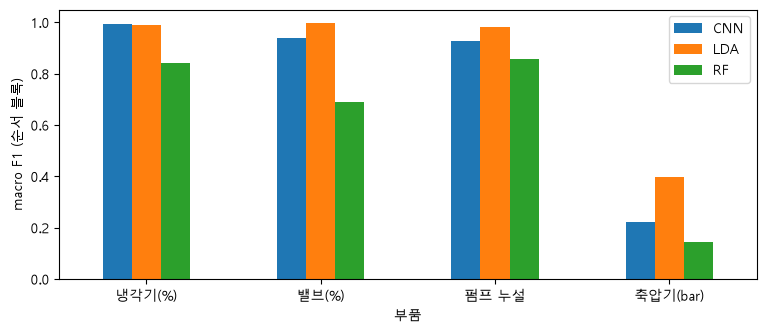

In [5]:
FEAT = features(cyc); X = cyc[FEAT].fillna(cyc[FEAT].median()); cv = KFold(5, shuffle=False); rows = []
for c in COMP:
    t0 = time.time(); y = cyc[c].values
    p = dict(CNN=cnn_cv(y), LDA=cross_val_predict(make_pipeline(StandardScaler(), LDA()), X, y, cv=cv),
             RF=cross_val_predict(RandomForestClassifier(300, random_state=SEED, n_jobs=-1), X, y, cv=cv))
    f1 = {k: f1_score(y, v, average="macro") for k, v in p.items()}; best = max(["LDA", "RF"], key=f1.get)
    a, b = p["CNN"] == y, p[best] == y; t = [[(a & b).sum(), (a & ~b).sum()], [(~a & b).sum(), (~a & ~b).sum()]]
    r = mcnemar(t, exact=False, correction=True)
    rows.append(dict(부품=COMP[c], CNN=f1["CNN"], LDA=f1["LDA"], RF=f1["RF"], 최고_통계ML=best, CNN만=t[0][1], 통계ML만=t[1][0], 통계량=r.statistic, p=r.pvalue))
    print(f"{COMP[c]} 완료 ({time.time() - t0:.0f}초)")
dl = pd.DataFrame(rows); dl["p_holm"] = holm(dl["p"])
dl["판정"] = np.where(dl.p_holm >= ALPHA, "차이 없음", np.where(dl.CNN > dl[["LDA", "RF"]].max(axis=1), "CNN 우세", "통계·ML 우세"))
display(dl.style.format({"CNN": "{:.3f}", "LDA": "{:.3f}", "RF": "{:.3f}", "통계량": "{:.1f}", "p": "{:.2e}", "p_holm": "{:.2e}"}))
fig, ax = plt.subplots(figsize=(9, 3.5)); dl.set_index("부품")[["CNN", "LDA", "RF"]].plot.bar(ax=ax, rot=0); ax.set_ylabel("macro F1 (순서 블록)"); ax.set_ylim(0, 1.05); plt.show()

## 4. 판단 기준과 결론

| 기준 | 우리 데이터 | 유리한 쪽 |
|---|---|---|
| 데이터 양 | 2,205 사이클, 자기상관 때문에 유효 표본은 훨씬 적음 (H06) | 통계·ML |
| 정상성 | 특징 대부분이 비정상, 드리프트 있음 (H05, H07) | 둘 다 불리. 딥러닝도 학습 범위 밖은 잘 못 맞힘 |
| 현재 성능 | 냉각기·밸브·펌프는 LDA가 순서 블록에서 0.98 이상 | 통계·ML (올릴 여지 작음) |
| 판단 근거 설명 (FR-06) | 화면에 판단 이유를 보여줘야 함 | 통계·ML |
| 개발 기간 | ML 개발 6일 (12/4~12/11) | 통계·ML |
| 원 파형 정보 | 밸브처럼 구간 정보가 중요 (H03) | 딥러닝 (스스로 구간을 찾음) |
| **비교 실험 (3절)** | 위 표의 판정 열 | **실험 결과로 최종 판단** |

In [6]:
win_dl = (dl.판정 == "CNN 우세").sum(); win_ml = (dl.판정 == "통계·ML 우세").sum()
acc = dl[dl.부품 == COMP["accumulator_bar"]].iloc[0]
print(f"CNN 우세 {win_dl}개, 통계·ML 우세 {win_ml}개, 차이 없음 {(dl.판정 == '차이 없음').sum()}개")
print(f"가장 어려운 축압기: CNN {acc.CNN:.3f} vs 최고 통계·ML {max(acc.LDA, acc.RF):.3f} → {acc.판정}")
decision = "통계·머신러닝을 주 방법으로 확정, 딥러닝은 비교 실험(부록)으로만 보고" if win_ml >= win_dl and acc.판정 != "CNN 우세" else "딥러닝 추가 검토 필요"
print("결론:", decision)
save_result("DL", title="통계·ML vs 딥러닝", test="McNemar (Holm)", stat=f"CNN 우세 {win_dl} / 통계·ML 우세 {win_ml}", p=float(dl.p_holm.max()),
            effect=f"축압기 CNN {acc.CNN:.2f} vs {max(acc.LDA, acc.RF):.2f}", verdict=decision)

CNN 우세 1개, 통계·ML 우세 3개, 차이 없음 0개
가장 어려운 축압기: CNN 0.224 vs 최고 통계·ML 0.396 → 통계·ML 우세
결론: 통계·머신러닝을 주 방법으로 확정, 딥러닝은 비교 실험(부록)으로만 보고
저장: results/DL.json


### 결론 (실행 결과 기준)

- 특징 대부분이 비정상이고(H05), 이웃 사이클끼리 강하게 닮았으며(H06), 부품 상태가 같아도 데이터가 흘러갑니다(H07). 그래서 **정상성을 가정하는 시계열 모델(ARIMA)은 쓰지 않고**, 평가는 순서 블록으로 합니다.
- 1D-CNN은 가장 어려운 **축압기에서 오히려 통계·ML보다 크게 낮았습니다.** 축압기가 어려운 원인은 모델의 복잡도가 아니라 온도 드리프트와 신호 가림(H04, H07)이기 때문입니다.
- **결론: 통계·머신러닝을 주 방법으로 확정하고, 딥러닝은 "비교했지만 이득이 없었다"는 근거로 SOA 부록에 넣습니다.** 남은 시간은 축압기의 온도·기준선 보정에 씁니다.
- **한계:**
  - 1초 평균 파형을 썼고, CNN 구조와 하이퍼파라미터를 튜닝하지 않았습니다.
  - 통계·ML은 특징 v1 기준입니다. 특징 v2에서는 통계·ML 쪽이 더 오를 것이라 결론이 바뀔 가능성은 낮습니다.